# MarketMind — Experiment 2: Gaussian Hidden Markov Model (HMM)

**Goal:** Test whether explicitly modelling temporal state transitions gives more useful market-regime sequences than static clustering.

This notebook continues from the real-data baseline experiment. It uses the same NIFTY 50 historical 1-minute CSV source, the same session-aware 15-minute OHLC bars, and the same six OHLC-only features. It does **not** use volume because the long historical series does not have consistent volume coverage.

### Methodological rules
- Chronological 70/30 split; never shuffle time-series observations.
- Fit the scaler and HMM using training data only.
- Keep the held-out test period as one contiguous chronological sequence.
- Use **causal forward-filtered probabilities** for test-time state probabilities. Do not use smoothed probabilities or full-sequence Viterbi paths as if they were real-time predictions.
- HMM state IDs are arbitrary. Interpret states using their feature profiles, not their numeric IDs.
- There are no independent ground-truth regime labels, so accuracy, ARI and NMI are not reported.

> HMM is a temporal probabilistic model, not another static clustering algorithm. Compare its held-out likelihood, state occupancy, transition behaviour, stability and eventual strategy performance—not silhouette score alone.

## 0. Install the additional dependency

Run this once in the notebook environment. If the kernel asks for a restart, restart it and continue from the top.

In [1]:
%pip install hmmlearn

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and project/data folder detection

This searches upward from the notebook working directory for the MarketMind project root, then looks for the extracted 1-minute CSV folder. You do not need to type a local Windows path.

In [2]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score  # imported only for clarity; not used without labels
from hmmlearn.hmm import GaussianHMM
from scipy.special import logsumexp

RANDOM_STATE = 42
TRAIN_FRACTION = 0.70
N_STATES_TO_TEST = [3, 4, 5]
MAX_TRAIN_ROWS = 20_000       # contiguous tail of the training period
MAX_TEST_ROWS = 10_000        # contiguous beginning of the held-out period
COVARIANCE_TYPE = "diag"     # robust starting point for correlated financial features
N_ITER = 150

cwd = Path.cwd().resolve()
possible_roots = [cwd, *cwd.parents]
ROOT = next((p for p in possible_roots if (p / "data" / "raw" / "nifty50" / "1min").exists()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Could not locate MarketMind/data/raw/nifty50/1min. "
        f"Notebook working directory is {cwd}. Keep the notebook inside MarketMind/research."
    )
DATA_DIR = ROOT / "data" / "raw" / "nifty50" / "1min"
OUT_DIR = ROOT / "research" / "hmm_results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

files = sorted(DATA_DIR.rglob("*.csv"))
print("Project root:", ROOT)
print("Data directory:", DATA_DIR)
print("CSV files found:", len(files))
if not files:
    raise FileNotFoundError(f"No CSV files found under {DATA_DIR}")


Project root: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind
Data directory: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\data\raw\nifty50\1min
CSV files found: 20


## 2. Load and validate the historical CSV files

The loader accepts the expected `Timestamp, Open, High, Low, Close` columns and parses timestamps consistently. It combines the CSV files, sorts chronologically, removes duplicate timestamps and invalid OHLC rows.

In [3]:
frames = []
file_audit = []
for path in files:
    df = pd.read_csv(path)
    required = ["Timestamp", "Open", "High", "Low", "Close"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        print(f"Skipping {path.name}: missing columns {missing}")
        continue
    df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")
    for c in ["Open", "High", "Low", "Close"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    if "Volume" in df.columns:
        df["Volume"] = pd.to_numeric(df["Volume"], errors="coerce")
    frames.append(df)
    file_audit.append({"file": str(path.relative_to(ROOT)), "rows": len(df),
                       "start": str(df["Timestamp"].min()), "end": str(df["Timestamp"].max())})

if not frames:
    raise ValueError("No CSV files with the required OHLC columns were loaded.")
raw = pd.concat(frames, ignore_index=True).sort_values("Timestamp")
raw = raw.dropna(subset=["Timestamp", "Open", "High", "Low", "Close"])
raw = raw.drop_duplicates(subset=["Timestamp"], keep="first")
raw = raw[(raw[["Open", "High", "Low", "Close"]] > 0).all(axis=1)]
raw = raw[raw["High"] >= raw[["Open", "Close", "Low"]].max(axis=1)]
raw = raw[raw["Low"] <= raw[["Open", "Close", "High"]].min(axis=1)]
raw = raw.set_index("Timestamp").sort_index()

# Regular NSE cash-market session; each session is resampled independently.
raw = raw.between_time("09:15", "15:29").copy()
raw["session_date"] = raw.index.date

def resample_session(day):
    day = day.drop(columns=["session_date"])
    agg = {"Open": "first", "High": "max", "Low": "min", "Close": "last"}
    out = day.resample("15min", origin="start_day", offset="9h15min",
                       label="left", closed="left").agg(agg)
    return out.dropna(subset=["Open", "High", "Low", "Close"])

bars = pd.concat([resample_session(g) for _, g in raw.groupby("session_date")]).sort_index()
bars = bars[(bars.index.time >= pd.Timestamp("09:15").time()) &
            (bars.index.time <= pd.Timestamp("15:15").time())]
print(f"Loaded files: {len(file_audit)} | cleaned 1-minute rows: {len(raw):,} | 15-minute bars: {len(bars):,}")
print("Coverage:", bars.index.min(), "to", bars.index.max())
display(pd.DataFrame(file_audit).head())
display(bars.head())


Loaded files: 20 | cleaned 1-minute rows: 890,607 | 15-minute bars: 59,378
Coverage: 2017-04-03 09:15:00 to 2026-11-17 15:15:00


,file,rows,start,end
0,data\raw\nifty50\1min\2017\NIFTY50_1min_2017.csv,69375,2017-04-03 09:15:00,2017-12-29 15:29:00
1,data\raw\nifty50\1min\2018\NIFTY50_1min_2018.csv,91874,2018-01-01 09:15:00,2018-12-31 15:29:00
2,data\raw\nifty50\1min\2019\NIFTY50_1min_2019.csv,91500,2019-01-01 09:15:00,2019-12-31 15:29:00
3,data\raw\nifty50\1min\2020\NIFTY50_1min_2020.csv,94125,2020-01-01 09:15:00,2020-12-31 15:29:00
4,data\raw\nifty50\1min\2021\NIFTY50_1min_2021.csv,92668,2021-01-01 09:15:00,2021-12-31 15:29:00


,Open,High,Low,Close
Timestamp,,,,
2017-04-03 09:15:00,9219.63,9221.75,9193.50,9200.35
2017-04-03 09:30:00,9200.65,9208.80,9195.35,9197.50
2017-04-03 09:45:00,9197.80,9205.60,9192.40,9202.35
2017-04-03 10:00:00,9202.05,9209.35,9201.90,9205.90
2017-04-03 10:15:00,9205.90,9207.20,9198.85,9201.30


## 3. Build the same six OHLC-only features as the baseline

These features are computed using current and past observations only. No centered rolling windows or future shifts are used.

In [4]:
close = bars["Close"]
prev_close = close.shift(1)
log_ret = np.log(close).diff()
delta = close.diff()
gain = delta.clip(lower=0).rolling(14, min_periods=14).mean()
loss = (-delta.clip(upper=0)).rolling(14, min_periods=14).mean()
rs = gain / loss.replace(0, np.nan)
rsi = 100 - (100 / (1 + rs))
tr = pd.concat([(bars["High"] - bars["Low"]),
                (bars["High"] - prev_close).abs(),
                (bars["Low"] - prev_close).abs()], axis=1).max(axis=1)
atr = tr.rolling(14, min_periods=14).mean()

features = pd.DataFrame(index=bars.index)
features["ret_5"] = np.log(close).diff(5) * 100
features["roll_vol"] = log_ret.rolling(20, min_periods=20).std() * 100
features["rsi"] = rsi
features["ma_diff"] = (close.rolling(20).mean() / close.rolling(50).mean() - 1) * 100
features["momentum"] = (close / close.shift(10) - 1) * 100
features["atr_pct"] = atr / close * 100
features = features.replace([np.inf, -np.inf], np.nan).dropna()

print("Feature rows:", len(features))
print("Features:", list(features.columns))
display(features.describe().T)


Feature rows: 59313
Features: ['ret_5', 'roll_vol', 'rsi', 'ma_diff', 'momentum', 'atr_pct']


,count,mean,std,min,25%,50%,75%,max
ret_5,59313.0,0.008375,0.450660,-11.497840,-0.152845,0.013180,0.174330,11.262615
roll_vol,59313.0,0.154018,0.127837,0.023405,0.091404,0.125586,0.178297,3.130192
rsi,59313.0,51.790650,19.132641,0.000000,37.471474,51.765376,66.362091,99.928622
ma_diff,59313.0,0.025616,0.501057,-5.031037,-0.219457,0.044475,0.289268,4.442814
momentum,59313.0,0.018783,0.637106,-12.380133,-0.240887,0.027888,0.288670,14.272556
atr_pct,59313.0,0.202110,0.127923,0.053371,0.133113,0.174461,0.233717,2.724547


## 4. Chronological train/test split and scaling

The HMM needs ordered sequences. Unlike the baseline clustering notebook, this experiment does not randomly sample rows. To keep training computationally practical, it uses a contiguous block from the end of the training period and a contiguous block from the beginning of the test period. The test block is never used to fit the scaler or model.

Each NSE trading session is passed as a separate HMM sequence (`lengths`). Overnight gaps are therefore not treated as ordinary 15-minute state transitions.

In [5]:
split_at = int(len(features) * TRAIN_FRACTION)
train_all = features.iloc[:split_at].copy()
test_all = features.iloc[split_at:].copy()

train = train_all.tail(min(MAX_TRAIN_ROWS, len(train_all))).copy()
test = test_all.head(min(MAX_TEST_ROWS, len(test_all))).copy()

scaler = StandardScaler()
Z_train = scaler.fit_transform(train)
Z_test = scaler.transform(test)

# Each trading day is a separate sequence. This prevents the model from treating
# the overnight market closure as an ordinary 15-minute transition.
train_lengths = train.groupby(train.index.date).size().tolist()
test_lengths = test.groupby(test.index.date).size().tolist()

print("Full chronological split:", len(train_all), "train /", len(test_all), "test")
print("HMM contiguous sequences:", len(Z_train), "train /", len(Z_test), "held-out test")
print("Train range:", train.index.min(), "to", train.index.max())
print("Test range:", test.index.min(), "to", test.index.max())
print("Training sessions:", len(train_lengths), "| test sessions:", len(test_lengths))
if len(Z_train) < 1000 or len(Z_test) < 100:
    raise ValueError("Not enough rows for a meaningful HMM experiment. Check data coverage.")


Full chronological split: 41519 train / 17794 test
HMM contiguous sequences: 20000 train / 10000 held-out test
Train range: 2020-09-30 14:45:00 to 2023-12-29 10:30:00
Test range: 2023-12-29 10:45:00 to 2025-08-11 12:30:00
Training sessions: 803 | test sessions: 402


## 5. Fit Gaussian HMMs with different state counts

We test 3, 4 and 5 hidden states. A diagonal covariance model is the initial choice to reduce parameter count and improve numerical stability. We record training likelihood, held-out likelihood, BIC, convergence and runtime. BIC is a model-selection aid, not proof that a state corresponds to a real economic regime.

In [6]:
def hmm_parameter_count(n_states, n_features, covariance_type="diag"):
    # Start probabilities: K-1; transition matrix: K*(K-1); means: K*D.
    count = (n_states - 1) + n_states * (n_states - 1) + n_states * n_features
    if covariance_type == "diag":
        count += n_states * n_features
    elif covariance_type == "full":
        count += n_states * n_features * (n_features + 1) // 2
    else:
        raise ValueError("This notebook supports diag or full covariance counting.")
    return count

models = {}
rows = []
for k in N_STATES_TO_TEST:
    model = GaussianHMM(
        n_components=k,
        covariance_type=COVARIANCE_TYPE,
        n_iter=N_ITER,
        tol=1e-3,
        random_state=RANDOM_STATE,
        min_covar=1e-4,
        implementation="log"
    )
    started = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        model.fit(Z_train, lengths=train_lengths)
    fit_seconds = time.perf_counter() - started
    train_loglik = model.score(Z_train, lengths=train_lengths)
    test_loglik = model.score(Z_test, lengths=test_lengths)
    n_params = hmm_parameter_count(k, Z_train.shape[1], COVARIANCE_TYPE)
    bic = -2 * train_loglik + n_params * np.log(len(Z_train))
    models[k] = model
    rows.append({
        "n_states": k,
        "covariance_type": COVARIANCE_TYPE,
        "train_log_likelihood": train_loglik,
        "train_loglik_per_observation": train_loglik / len(Z_train),
        "heldout_log_likelihood": test_loglik,
        "heldout_loglik_per_observation": test_loglik / len(Z_test),
        "bic": bic,
        "n_parameters": n_params,
        "converged": bool(model.monitor_.converged),
        "iterations": int(model.monitor_.iter),
        "fit_seconds": fit_seconds,
        "warning_count": len(caught)
    })
    print(f"Fitted {k}-state HMM in {fit_seconds:.1f}s; converged={model.monitor_.converged}; warnings={len(caught)}")

comparison = pd.DataFrame(rows).sort_values("bic")
display(comparison)
comparison.to_csv(OUT_DIR / "hmm_model_comparison.csv", index=False)


Fitted 3-state HMM in 95.5s; converged=True; warnings=0
Fitted 4-state HMM in 35.7s; converged=True; warnings=0
Fitted 5-state HMM in 88.7s; converged=True; warnings=0


,n_states,covariance_type,train_log_likelihood,train_loglik_per_observation,heldout_log_likelihood,heldout_loglik_per_observation,bic,n_parameters,converged,iterations,fit_seconds,warning_count
1,4,diag,-115745.868468,-5.787293,-54398.805239,-5.439881,232115.656651,63,True,63,35.675045,0
2,5,diag,-115727.594892,-5.786380,-54384.244204,-5.438424,232287.082738,84,True,150,88.721867,0
0,3,diag,-126331.530149,-6.316577,-61073.871950,-6.107387,253098.813750,44,True,150,95.532092,0


## 6. Causal forward filtering on the held-out test sequence

`predict_proba()` in many HMM workflows returns smoothed posteriors that can use future observations within the supplied sequence. For a real-time interpretation, this notebook instead calculates **forward-filtered probabilities**: the probability at timestamp *t* uses observations only up to *t*. The emission log-likelihood calculation uses hmmlearn’s Gaussian emission implementation; the forward recursion itself is explicit. The filter resets to the learned initial-state distribution at the start of each trading session, so it does not carry a 15-minute transition across the overnight closure.

In [7]:
def causal_forward_filter(model, X, lengths):
    """Causal filtered P(state_t | observations so far), resetting each session."""
    X = np.asarray(X)
    log_emission = model._compute_log_likelihood(X)
    log_trans = np.log(np.clip(model.transmat_, 1e-300, 1.0))
    filtered = np.empty((len(X), model.n_components), dtype=float)
    offset = 0
    for seq_len in lengths:
        stop = offset + int(seq_len)
        # Reset to the learned initial distribution at the start of each NSE session.
        log_alpha = np.log(np.clip(model.startprob_, 1e-300, 1.0)) + log_emission[offset]
        log_alpha -= logsumexp(log_alpha)
        filtered[offset] = np.exp(log_alpha)
        for t in range(offset + 1, stop):
            log_alpha = log_emission[t] + logsumexp(log_alpha[:, None] + log_trans, axis=0)
            log_alpha -= logsumexp(log_alpha)
            filtered[t] = np.exp(log_alpha)
        offset = stop
    if offset != len(X):
        raise ValueError("Sequence lengths do not sum to the number of observations.")
    return filtered

# Choose the candidate with the lowest BIC as a provisional statistical choice.
selected_k = int(comparison.iloc[0]["n_states"])
selected_model = models[selected_k]
filtered_probs = causal_forward_filter(selected_model, Z_test, test_lengths)
filtered_states = filtered_probs.argmax(axis=1)
confidence = filtered_probs.max(axis=1)

print("Provisional selected state count (lowest training BIC):", selected_k)
print("Mean maximum filtered state probability:", round(float(confidence.mean()), 4))
print("Filtered probability rows sum to 1:", np.allclose(filtered_probs.sum(axis=1), 1.0))


Provisional selected state count (lowest training BIC): 4
Mean maximum filtered state probability: 0.9603
Filtered probability rows sum to 1: True


## 7. State occupancy, transitions and feature profiles

State numbers are arbitrary. The feature profiles help describe what each state represents. Labels such as “bullish”, “sideways” or “high volatility” should be assigned only after inspecting the profile and validating behaviour across time periods.

In [8]:
state_series = pd.Series(filtered_states, index=test.index, name="hmm_state")
state_prob_df = pd.DataFrame(filtered_probs, index=test.index,
                             columns=[f"state_{i}_prob" for i in range(selected_k)])
state_prob_df["predicted_state"] = filtered_states
state_prob_df["max_state_probability"] = confidence

occupancy = state_series.value_counts(normalize=True).sort_index().rename("occupancy_pct") * 100
# Exclude overnight boundaries from transition and persistence calculations.
time_deltas = test.index.to_series().diff()
within_session = time_deltas <= pd.Timedelta(minutes=30)
prev_states = state_series.shift(1)[within_session]
next_states = state_series[within_session]
transition_counts = pd.crosstab(prev_states, next_states, dropna=True)
transition_probs = transition_counts.div(transition_counts.sum(axis=1), axis=0).fillna(0)

profile = train.copy()
profile["state"] = selected_model.predict(Z_train, lengths=train_lengths)
state_profile = profile.groupby("state").mean()

print("Test state occupancy (%):")
display(occupancy.to_frame())
print("Training state feature profiles (original feature units):")
display(state_profile)
print("Estimated transition probabilities from filtered test states:")
display(transition_probs)

state_series.to_csv(OUT_DIR / "hmm_test_states.csv", header=True)
state_prob_df.to_csv(OUT_DIR / "hmm_test_filtered_probabilities.csv")
state_profile.to_csv(OUT_DIR / "hmm_state_feature_profiles.csv")
transition_probs.to_csv(OUT_DIR / "hmm_test_transition_matrix.csv")


Test state occupancy (%):


,occupancy_pct
hmm_state,
0,30.67
1,38.22
2,21.85
3,9.26


Training state feature profiles (original feature units):


,ret_5,roll_vol,rsi,ma_diff,momentum,atr_pct
state,,,,,,
0,-0.188665,0.148142,35.558229,-0.088327,-0.345410,0.208947
1,0.037002,0.089584,56.206748,0.158281,0.071105,0.129252
2,0.234866,0.156535,69.934258,0.223337,0.463138,0.202289
3,-0.028758,0.299836,48.138114,-0.208059,-0.079820,0.339026


Estimated transition probabilities from filtered test states:


hmm_state,0,1,2,3
hmm_state,,,,
0.0,0.922117,0.036750,0.031355,0.009777
1.0,0.025670,0.960379,0.013951,0.000000
2.0,0.039307,0.055218,0.901731,0.003744
3.0,0.039604,0.003300,0.022002,0.935094


## 8. Visualise held-out state sequence and confidence

The plotted state assignments are causal filtered predictions. They are not ground-truth labels. A state that occupies almost all observations or changes implausibly often may indicate a poorly specified model.

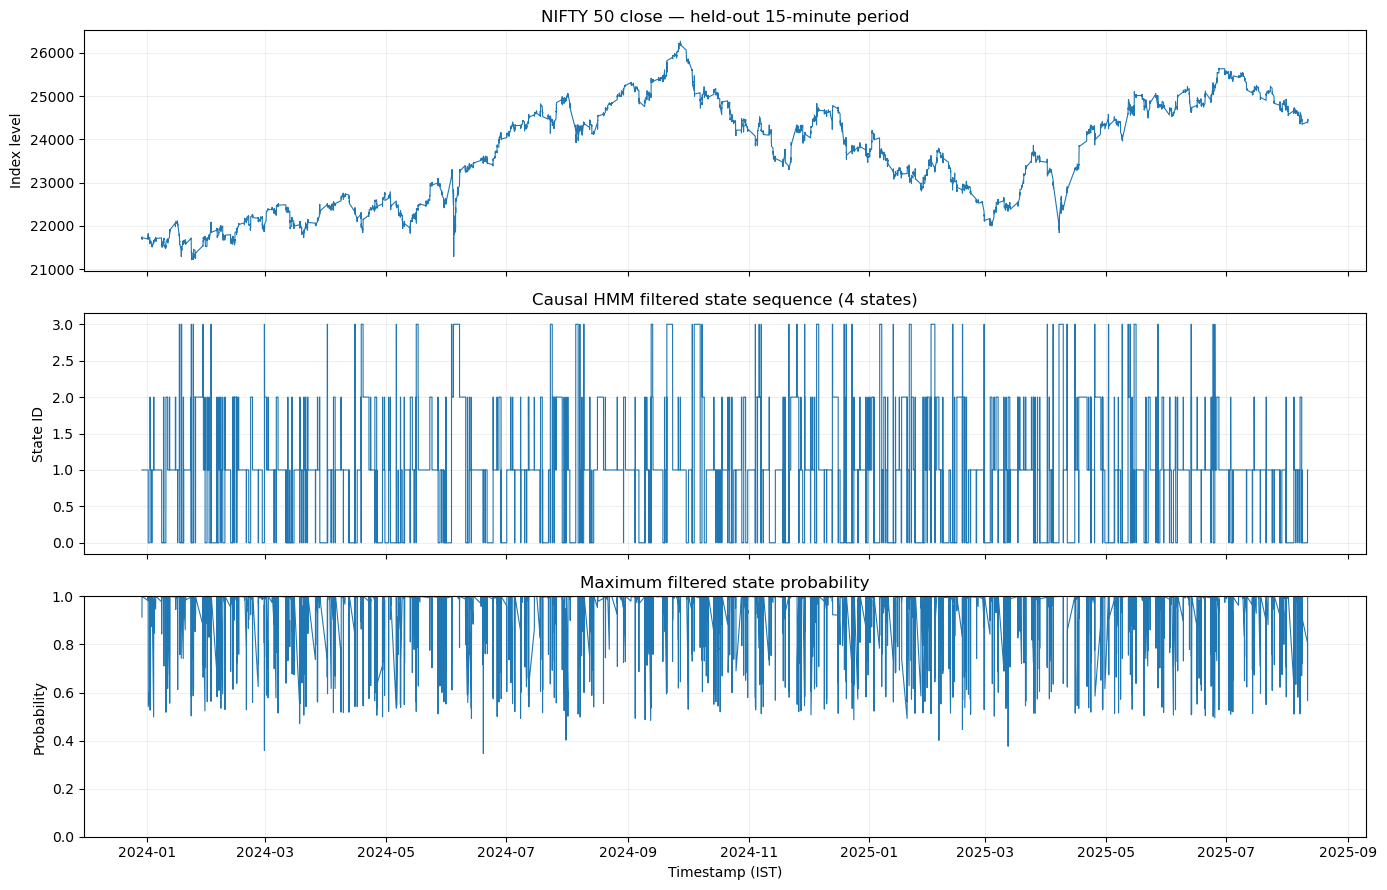

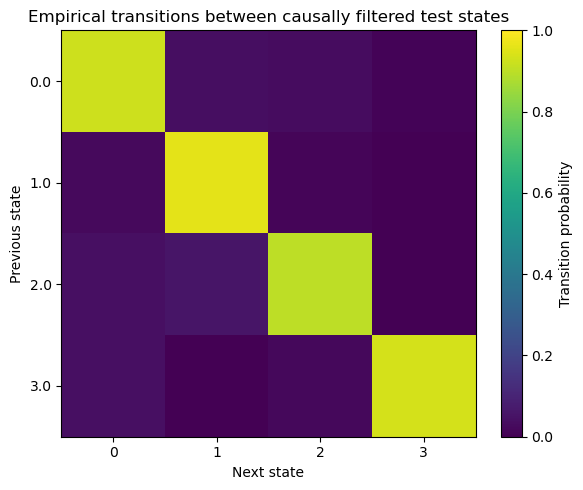

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
axes[0].plot(test.index, bars.loc[test.index, "Close"], linewidth=0.8)
axes[0].set_title("NIFTY 50 close — held-out 15-minute period")
axes[0].set_ylabel("Index level")
axes[1].step(test.index, filtered_states, where="post", linewidth=0.8)
axes[1].set_title(f"Causal HMM filtered state sequence ({selected_k} states)")
axes[1].set_ylabel("State ID")
axes[2].plot(test.index, confidence, linewidth=0.8)
axes[2].set_ylim(0, 1)
axes[2].set_title("Maximum filtered state probability")
axes[2].set_ylabel("Probability")
axes[2].set_xlabel("Timestamp (IST)")
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
plt.imshow(transition_probs, vmin=0, vmax=1, aspect="auto")
plt.colorbar(label="Transition probability")
plt.xticks(range(selected_k), transition_probs.columns)
plt.yticks(range(selected_k), transition_probs.index)
plt.title("Empirical transitions between causally filtered test states")
plt.xlabel("Next state")
plt.ylabel("Previous state")
plt.tight_layout()
plt.show()


## 9. Persistence and run-length diagnostics

High persistence is not automatically good: a model that predicts one state almost all the time can look stable but fail to distinguish regimes. Read persistence together with occupancy, state profiles, transition matrix and held-out likelihood.

In [10]:
time_deltas = test.index.to_series().diff()
within_session = time_deltas <= pd.Timedelta(minutes=30)
persistence_pct = float((state_series.diff()[within_session] == 0).mean() * 100)

# Calculate run lengths separately within each session, never across overnight gaps.
run_lengths = []
for _, session_states in state_series.groupby(state_series.index.date):
    values = session_states.to_numpy()
    if len(values):
        changes = np.r_[0, np.flatnonzero(np.diff(values) != 0) + 1, len(values)]
        run_lengths.extend(np.diff(changes).tolist())
run_lengths = np.asarray(run_lengths, dtype=int)
run_summary = {
    "selected_states": selected_k,
    "heldout_rows": len(test),
    "adjacent_state_persistence_pct": persistence_pct,
    "mean_run_length_bars": float(run_lengths.mean()),
    "median_run_length_bars": float(np.median(run_lengths)),
    "max_run_length_bars": int(run_lengths.max()),
    "mean_max_filtered_probability": float(confidence.mean()),
    "min_state_occupancy_pct": float(occupancy.min()),
    "max_state_occupancy_pct": float(occupancy.max())
}
display(pd.Series(run_summary, name="value").to_frame())
(OUT_DIR / "hmm_diagnostics.json").write_text(json.dumps(run_summary, indent=2))


,value
selected_states,4.000000
heldout_rows,10000.000000
adjacent_state_persistence_pct,93.309712
mean_run_length_bars,9.569378
median_run_length_bars,8.000000
max_run_length_bars,25.000000
mean_max_filtered_probability,0.960279
min_state_occupancy_pct,9.260000
max_state_occupancy_pct,38.220000


339

## 10. Save experiment metadata and interpret responsibly

This notebook does not automatically promote the HMM into the MarketMind production application. The next research stage should compare this model with baseline clustering over identical walk-forward folds, then test strategy outcomes with realistic transaction costs and slippage.

In [11]:
metadata = {
    "experiment": "Gaussian HMM regime detection",
    "dataset": "Bundled NIFTY 50 1-minute CSV files",
    "resampled_timeframe": "15min",
    "feature_columns": list(features.columns),
    "feature_note": "Six OHLC-only features; volume excluded for consistent long-term coverage",
    "chronological_split": "70/30",
    "hmm_train_rows": int(len(train)),
    "hmm_test_rows": int(len(test)),
    "train_start": str(train.index.min()),
    "train_end": str(train.index.max()),
    "test_start": str(test.index.min()),
    "test_end": str(test.index.max()),
    "state_counts_tested": N_STATES_TO_TEST,
    "covariance_type": COVARIANCE_TYPE,
    "selected_state_count_by_training_bic": selected_k,
    "test_probabilities": "causal forward-filtered; no future test observations used at each timestamp",
    "ground_truth_regime_labels_available": False,
    "limitations": [
        "No independent ground-truth regime labels; accuracy, ARI and NMI are not reported.",
        "Lowest training BIC is only a provisional state-count choice.",
        "Held-out likelihood is evaluated on one contiguous test block.",
        "The selected HMM is not automatically the most profitable trading model.",
        "Causal filtering uses hmmlearn Gaussian emission likelihoods; do not replace with smoothed posteriors for live use.",
        "Production integration requires separate walk-forward validation and transaction-cost-aware strategy tests."
    ]
}
(OUT_DIR / "hmm_experiment_metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved HMM experiment outputs to:", OUT_DIR.resolve())
print("Files:")
for p in sorted(OUT_DIR.iterdir()):
    print(" -", p.name)


Saved HMM experiment outputs to: D:\College_Stuff\Sem_5\Machine_Learning\CP\final\2\MarketMind\research\hmm_results
Files:
 - hmm_diagnostics.json
 - hmm_experiment_metadata.json
 - hmm_model_comparison.csv
 - hmm_state_feature_profiles.csv
 - hmm_test_filtered_probabilities.csv
 - hmm_test_states.csv
 - hmm_test_transition_matrix.csv
